# Final Project

## Part 0 Project Proposal
Before we do the project, you will need to create a repository
1. Create the project remotely on GitHub.  You will want to include a README
2. Install GitHub Desktop.
3. From the remote repo, clone down to your local and use github desktop to create it.
4. Copy the notebook into your local repo
5. Commit and push

***Invite me and the GA to your repo***

As you make changes locally, commit and push them. 

To complete the proposal. You will record the following in your README

1. The kind of data you want to find
2. The question/s you want to answer with the data.
3. URLs for the site/s that have the data you want.

***Note: You must aquire the data via an API or Web scraping.  Downloading a file will not get points.***

All code for your project will be recorded in this note book. Create extra code cells as needed.


# Part 1: Data aquisition
    1. Get raw data and put it into files. If needed, gather a representative amount of data.  Then append additional data as available.
    


In [1]:
# Part 1: Put code here
from api_key import API_KEY
import cfbd
import json

configuration = cfbd.Configuration()
configuration.access_token = API_KEY
api_client = cfbd.ApiClient(configuration)
stats_api = cfbd.StatsApi(api_client)
games_api = cfbd.GamesApi(api_client)
season_stats = stats_api.get_team_stats(year=2025)

with open('raw_season_stats.json', 'w') as f:
    json.dump([s.to_dict() for s in season_stats], f)
records = games_api.get_records(year=2025)

with open('raw_records.json', 'w') as f:
    json.dump([r.to_dict() for r in records], f)

## Part 2 Data processing

1. Process the raw data and store results in a file as needed.
2. Do analysis of the data
   

In [2]:
#Part 2: Put code here
import pandas as pd
import json
import seaborn as sns
import matplotlib.pyplot as plt

with open('raw_records.json', 'r') as f:
    records_data = json.load(f)

with open('raw_season_stats.json', 'r') as f:
    stats_data = json.load(f)

records_list = []
for r in records_data:
    if 'total' in r and isinstance(r['total'], dict):
        records_list.append({'team': r['team'], 'conference': r['conference'], 'wins': r['total']['wins']})

df_records = pd.DataFrame(records_list)
target_conferences = ['Big Ten', 'Big 12', 'SEC', 'ACC']
df_records = df_records[df_records['conference'].isin(target_conferences)]
df_stats_raw = pd.DataFrame(stats_data)
df_stats = df_stats_raw.pivot(index='team', columns='statName', values='statValue').reset_index()
df_merged = pd.merge(df_records, df_stats, on='team', how='inner')
df_merged['turnover_margin'] = df_merged['turnoversOpponent'] - df_merged['turnovers']
df_merged['net_yardage'] = df_merged['totalYards'] - df_merged['totalYardsOpponent']

df_merged.to_csv('power4_analysis_data.csv', index=False)
print("Analysis ready for", len(df_merged), "teams across the ACC, Big 12, Big Ten, and SEC.")

Analysis ready for 67 teams across the ACC, Big 12, Big Ten, and SEC.


To get the data needed, I had to pull offensive, defensive and season stats like record from the database so that I could analyze the teams based on their offense and defense to see if having a better offense gives you a better chance of winning, rather than having a better defense. Instead of doing every college football team, I decided to pull from the 4 major conferences in college football because they have the most stats and consistently play the same level of high competition and face each other often. This will make the data more usable because you can see a direct correlation between wins and offense or defensive stats, as well as net yards and wins. Meaning that you can effectively see if offense or defensive is more important when it comes to winning games.

## Part 3 Visualization

1. Create good graphs
2. Give narative conclusions explaining what is being demonstrated in the visualizations.

   

C:\Users\s560346\AppData\Local\Temp\ipykernel_3228\1262322349.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_merged, x='conference', y='wins', palette='Set2')


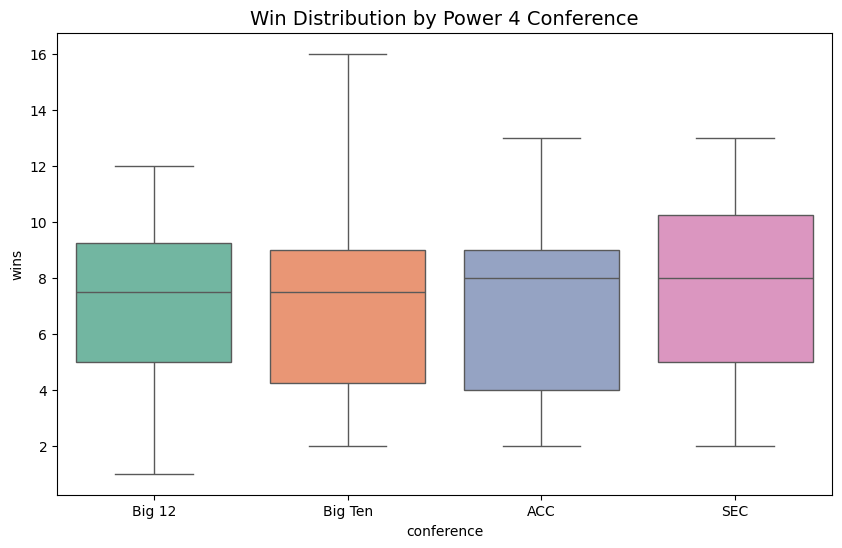

C:\Users\s560346\AppData\Local\Temp\ipykernel_3228\1262322349.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_merged, x='conference', y='off_points_per_100yds', palette='Set2')


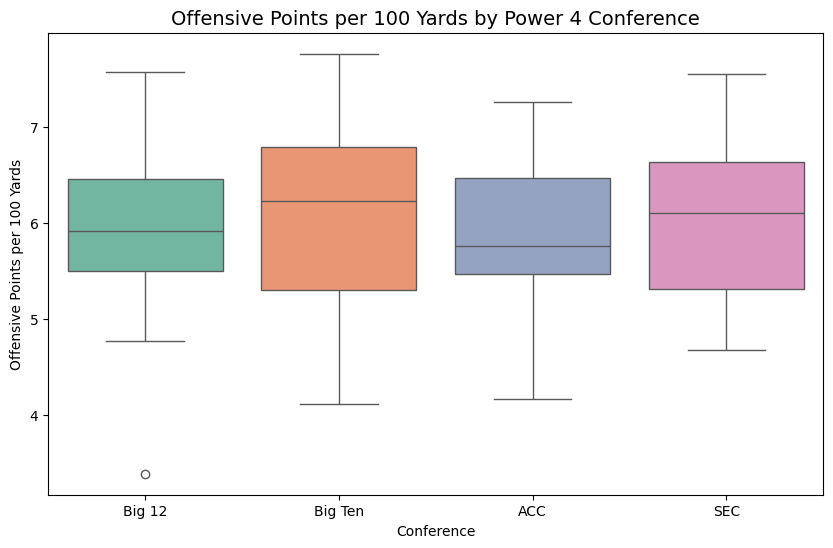

C:\Users\s560346\AppData\Local\Temp\ipykernel_3228\1262322349.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_merged, x='conference', y='def_points_per_100yds', palette='Set2')


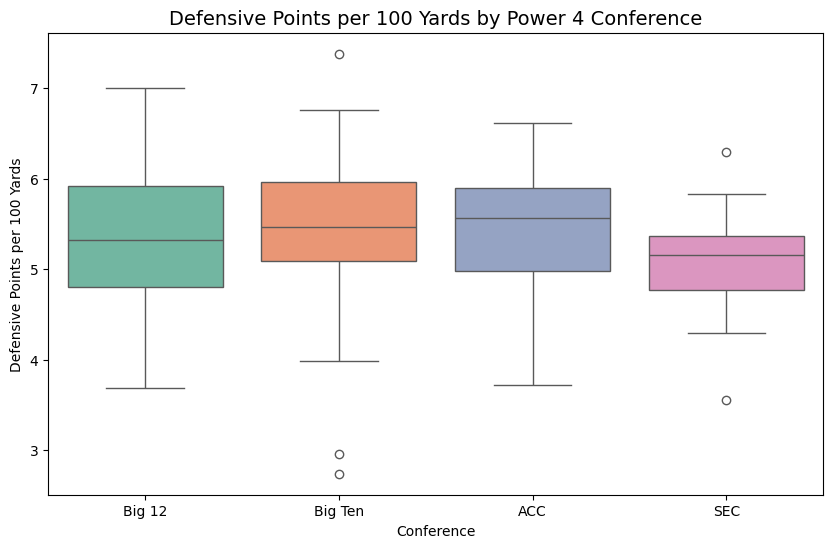

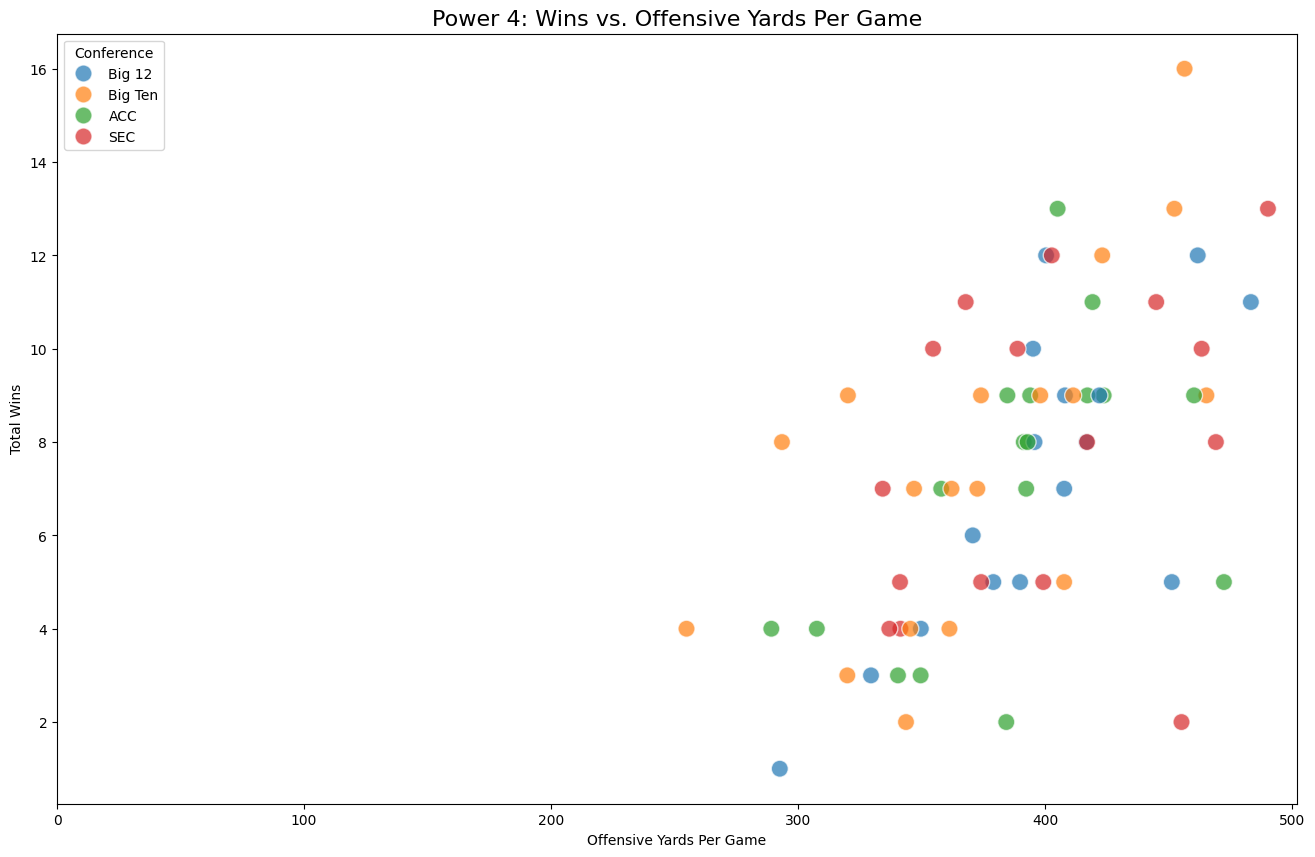

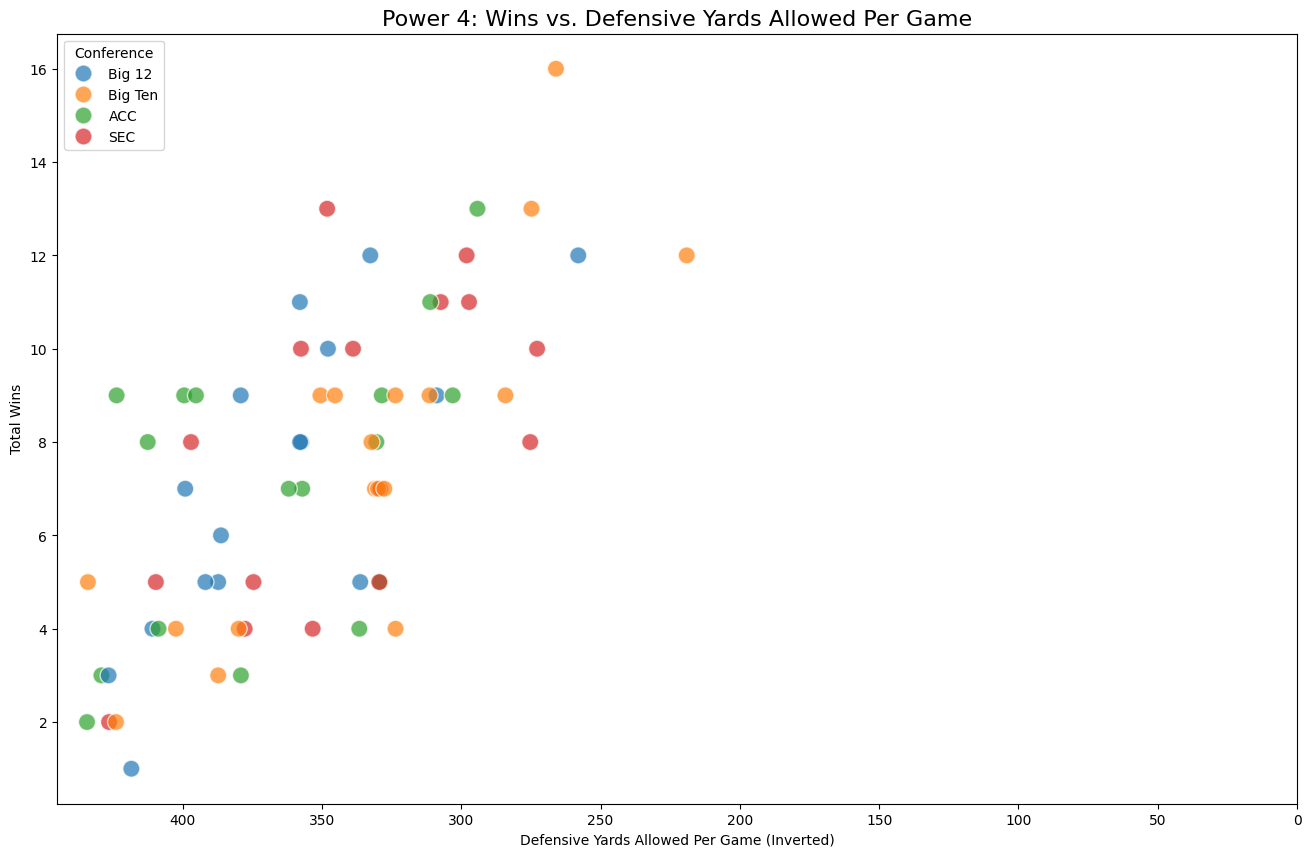

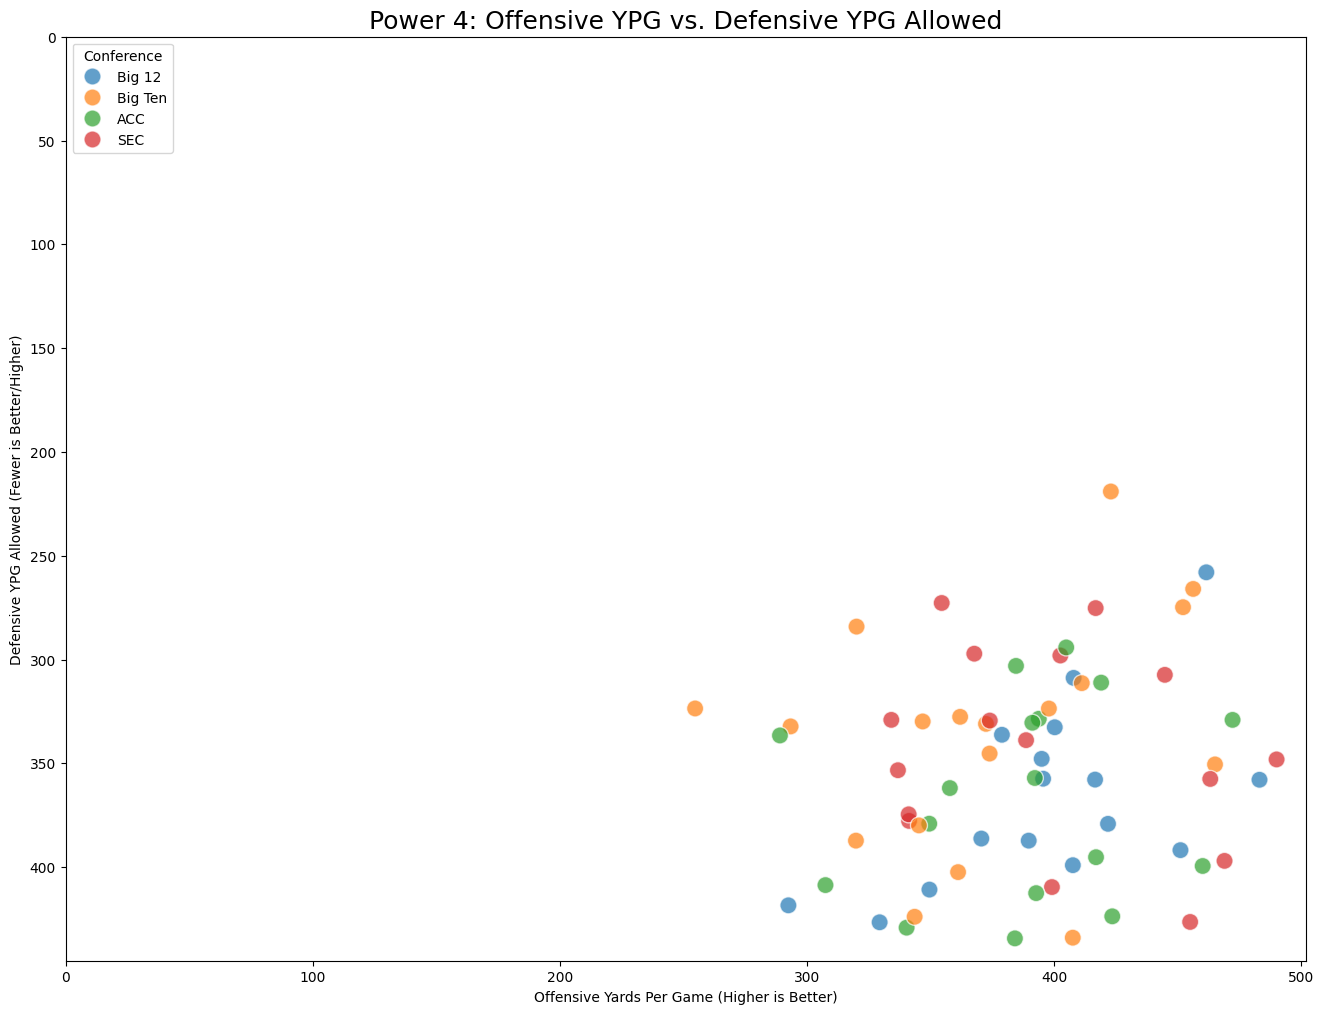

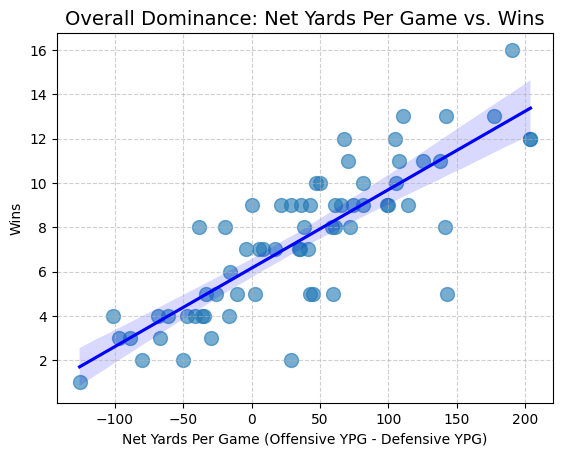

In [12]:
#Part 3: Put code here
import matplotlib.pyplot as plt
import seaborn as sns

df_merged['off_ypg'] = df_merged['totalYards'] / df_merged['games']
df_merged['def_ypg'] = df_merged['totalYardsOpponent'] / df_merged['games']

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_merged, x='conference', y='wins', palette='Set2')
plt.title('Win Distribution by Power 4 Conference', fontsize=14)
plt.show()

df_merged['estimated_points'] = (df_merged['passingTDs'] + df_merged['rushingTDs']) * 7
df_merged['off_points_per_100yds'] = (df_merged['estimated_points'] / df_merged['totalYards']) * 100

df_merged['estimated_points_allowed'] = (df_merged['passingTDsOpponent'] + df_merged['rushingTDsOpponent']) * 7
df_merged['def_points_per_100yds'] = (df_merged['estimated_points_allowed'] / df_merged['totalYardsOpponent']) * 100

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_merged, x='conference', y='off_points_per_100yds', palette='Set2')
plt.title('Offensive Points per 100 Yards by Power 4 Conference', fontsize=14)
plt.xlabel('Conference')
plt.ylabel('Offensive Points per 100 Yards')
plt.savefig('off_points_per_100yds_by_conference.png', dpi=300)
plt.show()

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_merged, x='conference', y='def_points_per_100yds', palette='Set2')
plt.title('Defensive Points per 100 Yards by Power 4 Conference', fontsize=14)
plt.xlabel('Conference')
plt.ylabel('Defensive Points per 100 Yards')
plt.savefig('def_points_per_100yds_by_conference.png', dpi=300)
plt.show()

plt.figure(figsize=(16, 10))
sns.scatterplot(data=df_merged, x='off_ypg', y='wins', hue='conference', s=150, alpha=0.7)
plt.xlim(left=0)
plt.title('Power 4: Wins vs. Offensive Yards Per Game', fontsize=16)
plt.xlabel('Offensive Yards Per Game')
plt.ylabel('Total Wins')
plt.legend(loc='upper left', title='Conference', fontsize=10)
plt.show()

plt.figure(figsize=(16, 10))
sns.scatterplot(data=df_merged, x='def_ypg', y='wins', hue='conference', s=150, alpha=0.7)
plt.gca().invert_xaxis()
plt.xlim(right=0) 
plt.title('Power 4: Wins vs. Defensive Yards Allowed Per Game', fontsize=16)
plt.xlabel('Defensive Yards Allowed Per Game (Inverted)')
plt.ylabel('Total Wins')
plt.legend(loc='upper left', title='Conference', fontsize=10)
plt.show()

plt.figure(figsize=(16, 12))
sns.scatterplot(data=df_merged, x='off_ypg', y='def_ypg', hue='conference', s=150, alpha=0.7)
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.gca().invert_yaxis()
plt.title('Power 4: Offensive YPG vs. Defensive YPG Allowed', fontsize=18)
plt.xlabel('Offensive Yards Per Game (Higher is Better)')
plt.ylabel('Defensive YPG Allowed (Fewer is Better/Higher)')
plt.legend(loc='upper left', title='Conference', fontsize=10)
plt.show()

sns.regplot(data=df_merged, x='net_ypg', y='wins', scatter_kws={'s':100, 'alpha':0.6},  line_kws={"color": "blue"})
plt.title('Overall Dominance: Net Yards Per Game vs. Wins', fontsize=14)
plt.xlabel('Net Yards Per Game (Offensive YPG - Defensive YPG)')
plt.ylabel('Wins')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

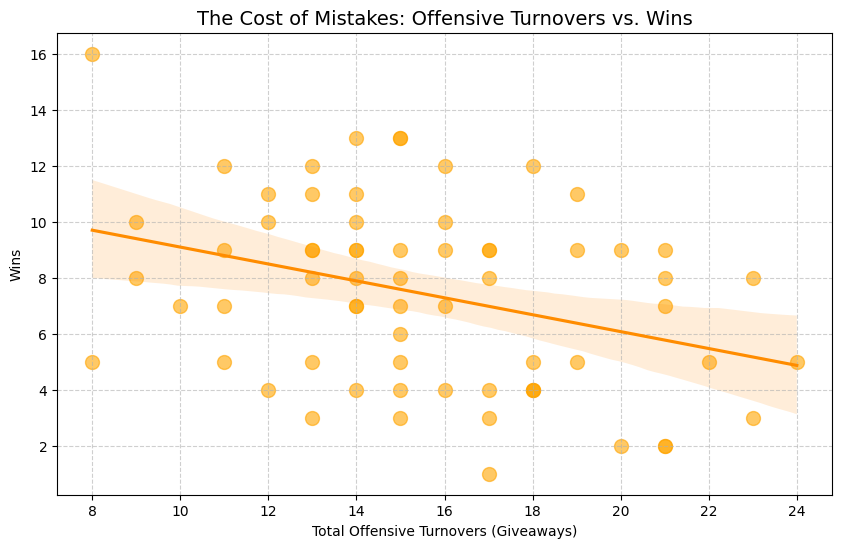

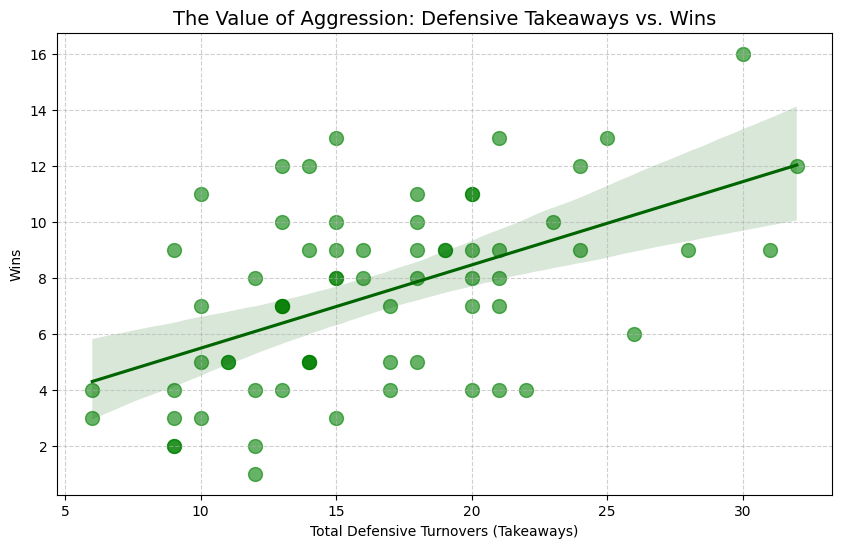

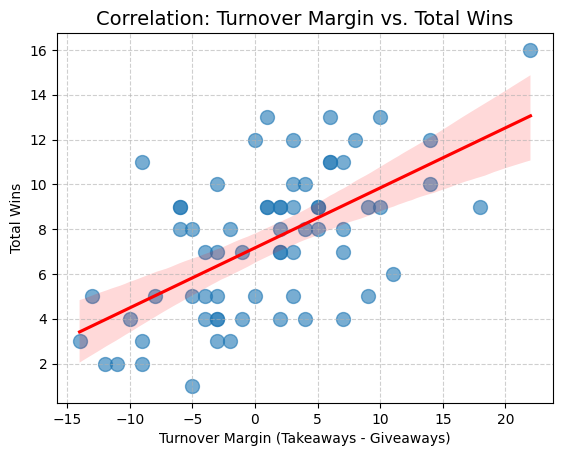

In [13]:
#More calculations and graphs about turnovers and win 
df_merged['net_ypg'] = (df_merged['totalYards'] - df_merged['totalYardsOpponent']) / df_merged['games']

plt.figure(figsize=(10, 6))
sns.regplot(data=df_merged, x='turnovers', y='wins', scatter_kws={'s':100, 'alpha':0.6, 'color': 'orange'},  line_kws={"color": "darkorange"})
plt.title('The Cost of Mistakes: Offensive Turnovers vs. Wins', fontsize=14)
plt.xlabel('Total Offensive Turnovers (Giveaways)')
plt.ylabel('Wins')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

plt.figure(figsize=(10, 6))
sns.regplot(data=df_merged, x='turnoversOpponent', y='wins', scatter_kws={'s':100, 'alpha':0.6, 'color': 'green'}, line_kws={"color": "darkgreen"})
plt.title('The Value of Aggression: Defensive Takeaways vs. Wins', fontsize=14)
plt.xlabel('Total Defensive Turnovers (Takeaways)')
plt.ylabel('Wins')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

sns.regplot(data=df_merged, x='turnover_margin', y='wins', scatter_kws={'s':100, 'alpha':0.6}, line_kws={"color": "red"})
plt.title('Correlation: Turnover Margin vs. Total Wins', fontsize=14)
plt.xlabel('Turnover Margin (Takeaways - Giveaways)')
plt.ylabel('Total Wins')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()